# Telco Customer Churn: Exploratory Data Analysis, Visualization and Deep Learning (MLP)

**Course assignment:** Case Study on EDA and Visualization of a Real-World Dataset (CO3, CO4, CO5)

**Problem:** A telecom company loses revenue when customers leave (churn). If we can understand *who* churns and *why*, and predict churners early, the company can target retention offers.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 fields: 20 predictors + 1 target).

**Pipeline (follows the 7 stages of visualization):**
1. Acquire  2. Parse  3. Filter  4. Mine  5. Represent  6. Refine  7. Interact

In [1]:
# ---------- Imports and global configuration ----------
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
random.seed(SEED); np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

FIG_DIR = "../figures"; os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## Stage 1: ACQUIRE: Load the dataset

In [2]:
DATA_PATH = "../data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Stage 2: PARSE: Understand structure and data types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Field groups used throughout the notebook
target = "Churn"
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]   # TotalCharges is stored as text, fixed below
binary_like  = ["SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in numeric_cols + [target, "customerID", "SeniorCitizen"]]
print(len(df.columns), "fields in total")
print("Categorical:", cat_cols)

21 fields in total
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Data cleaning (part of the Filter stage)
We handle **missing values, duplicates, outliers and wrong data types**.

In [5]:
# --- 1. Data type problem: TotalCharges is text because 11 rows hold a blank string ---
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan), errors="coerce")

# --- 2. Missing values ---
miss = df.isna().sum(); print("Missing values per column:\n", miss[miss > 0])
print("\nTenure of rows with missing TotalCharges:", df.loc[df.TotalCharges.isna(), "tenure"].unique())

Missing values per column:
 TotalCharges    11
dtype: int64

Tenure of rows with missing TotalCharges: [0]


In [6]:
# All 11 blanks belong to brand-new customers (tenure = 0) who have not been billed yet.
# So the correct value is 0 (not the mean/median), which avoids inventing charges.
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# --- 3. Duplicates ---
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

# --- 4. Drop identifier (carries no predictive information) ---
df = df.drop(columns="customerID")

# --- 5. Consistency: 'No internet service' / 'No phone service' are equivalent to 'No' ---
for c in ["MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})

# --- 6. Target encoding for analysis ---
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print("Missing values after cleaning:", int(df.isna().sum().sum()))

Duplicate rows       : 0
Duplicate customerIDs: 0
Missing values after cleaning: 0


In [7]:
# --- 7. Outlier detection with the IQR rule (1.5 x IQR) ---
rows = []
for c in numeric_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append([c, lo, hi, ((df[c] < lo) | (df[c] > hi)).sum()])
pd.DataFrame(rows, columns=["feature", "lower_fence", "upper_fence", "n_outliers"])

,feature,lower_fence,upper_fence,n_outliers
0,tenure,-60.000,124.000,0
1,MonthlyCharges,-46.025,171.375,0
2,TotalCharges,-4683.525,8868.675,0


**Outlier decision:** no feature has points outside the IQR fences. Charges and tenure are bounded business quantities, so we keep every row and apply standardization later.

## Stage 3: FILTER: Descriptive statistics

In [8]:
df[numeric_cols + ["SeniorCitizen"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80
SeniorCitizen,7043.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00


In [9]:
# Skewness and kurtosis (shape of each numeric distribution)
shape = pd.DataFrame({"skew": df[numeric_cols].skew(), "kurtosis": df[numeric_cols].kurt()}).round(3)
shape

,skew,kurtosis
tenure,0.240,-1.387
MonthlyCharges,-0.221,-1.257
TotalCharges,0.963,-0.229


## Stage 4: MINE: Statistical analysis (CO4)
### 4.1 Univariate analysis

In [10]:
# Frequency tables for categorical features
for c in ["Contract", "InternetService", "PaymentMethod"]:
    print(df[c].value_counts(normalize=True).mul(100).round(1).to_string(), "\n")
print("Churn rate overall: %.2f%%" % (df.ChurnFlag.mean()*100))

Contract
Month-to-month    55.0
Two year          24.1
One year          20.9 

InternetService
Fiber optic    44.0
DSL            34.4
No             21.7 

PaymentMethod
Electronic check             33.6
Mailed check                 22.9
Bank transfer (automatic)    21.9
Credit card (automatic)      21.6 

Churn rate overall: 26.54%


## Stage 5: REPRESENT: Data visualizations
Each plot is followed by *what it shows*, *why we made it* and *insights*.

### Visual 1: Target class distribution

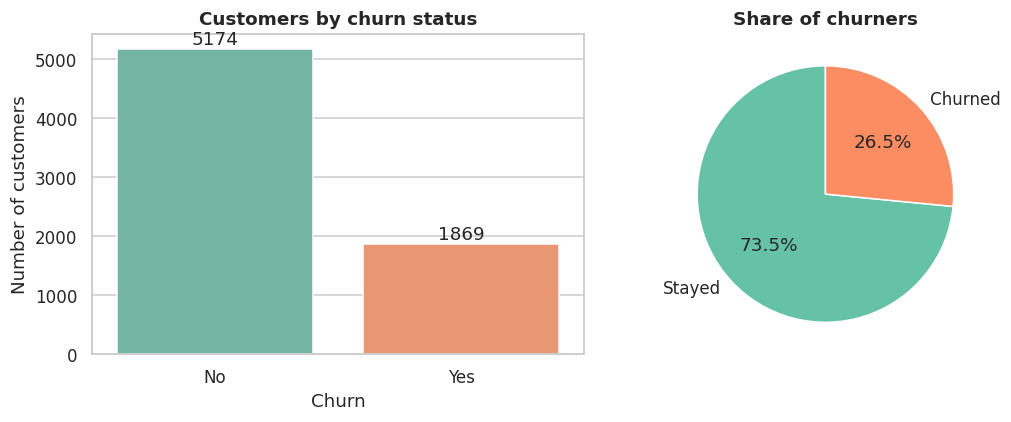

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = df["Churn"].value_counts()
sns.countplot(data=df, x="Churn", order=["No","Yes"], ax=ax[0], palette=["#66c2a5","#fc8d62"])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax[0].set_title("Customers by churn status"); ax[0].set_ylabel("Number of customers")
ax[1].pie(counts[["No","Yes"]], labels=["Stayed","Churned"], autopct="%1.1f%%", colors=["#66c2a5","#fc8d62"], startangle=90)
ax[1].set_title("Share of churners")
savefig("v1_churn_distribution")

**What it shows:** how many customers stayed vs left. **Why:** class balance decides which evaluation metrics and training strategy we need.
**Insight:** only about 26.5% of customers churn, so the data is imbalanced (about 2.8 : 1). Accuracy alone would be misleading (predicting "No" for everyone gives about 73.5%), so we will use ROC-AUC, recall and F1 and apply class weights during training.

### Visual 2: Distribution of numerical features

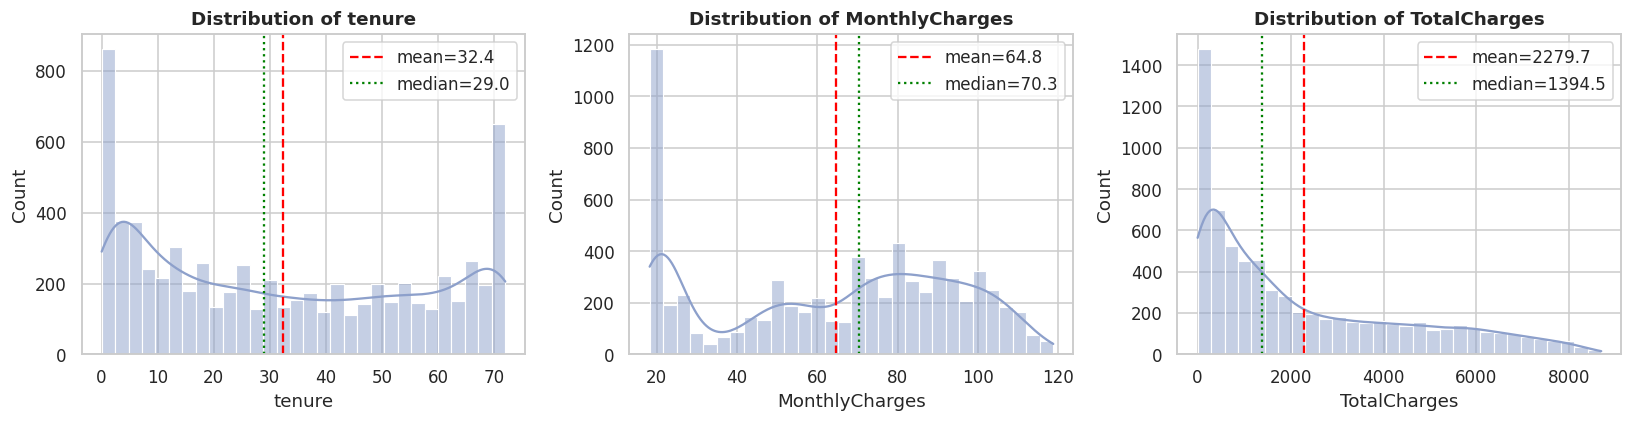

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, numeric_cols):
    sns.histplot(df[c], kde=True, bins=30, ax=ax, color="#8da0cb")
    ax.axvline(df[c].mean(), color="red", ls="--", label=f"mean={df[c].mean():.1f}")
    ax.axvline(df[c].median(), color="green", ls=":", label=f"median={df[c].median():.1f}")
    ax.set_title(f"Distribution of {c}"); ax.legend()
savefig("v2_numeric_histograms")

**What it shows:** the shape of tenure, monthly charges and total charges. **Why:** shape tells us about skew, modality and whether scaling or transforms are needed.
**Insight:** `tenure` is U-shaped (many brand-new customers and many loyal 70+ month customers). `MonthlyCharges` is multimodal, with a big group at the cheapest tier (about $20, phone-only) and another around $70-$100. `TotalCharges` is strongly right-skewed (skew about 0.96) because it grows with tenure.

### Visual 3: Boxplots of numeric features by churn status

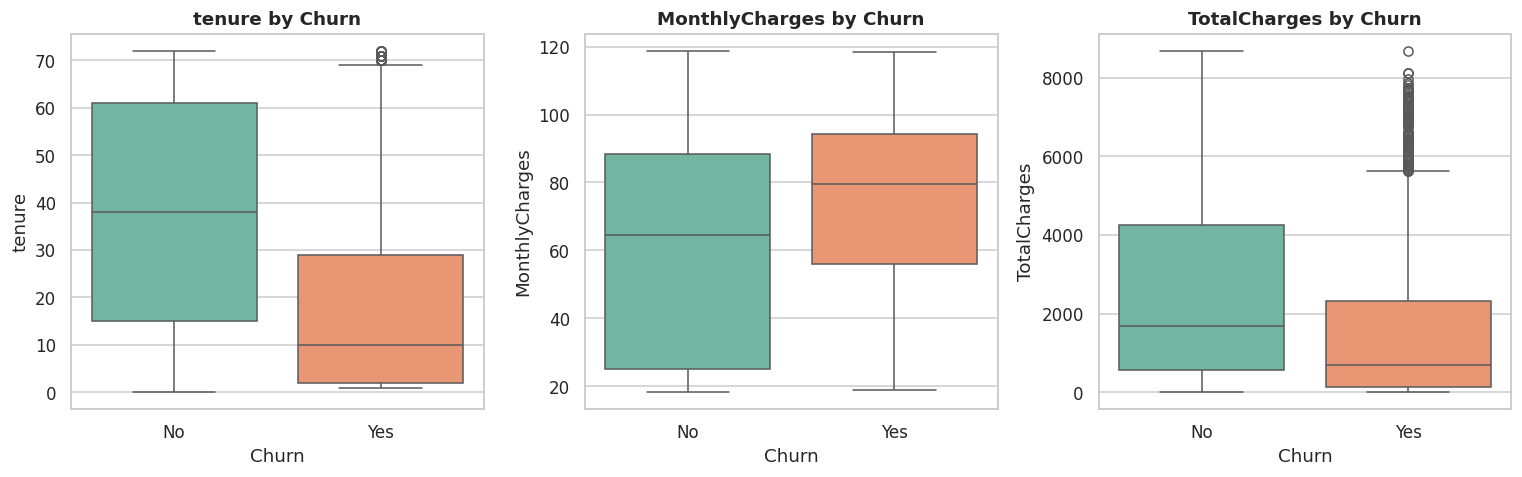

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1679.5
Yes      10.0            79.6         703.6


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, c in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Churn", y=c, order=["No","Yes"], ax=ax, palette=["#66c2a5","#fc8d62"])
    ax.set_title(f"{c} by Churn")
savefig("v3_boxplots_by_churn")
print(df.groupby("Churn")[numeric_cols].median().round(1))

**What it shows:** the median, spread and range of each numeric feature, split by churn. **Why:** to see which numeric variables separate churners from non-churners.
**Insight:** churners have a much lower median tenure (about 10 months vs 38) and *higher* monthly charges (about $80 vs $65). New customers on expensive plans are the riskiest group.

### Visual 4: Churn rate by key categorical features

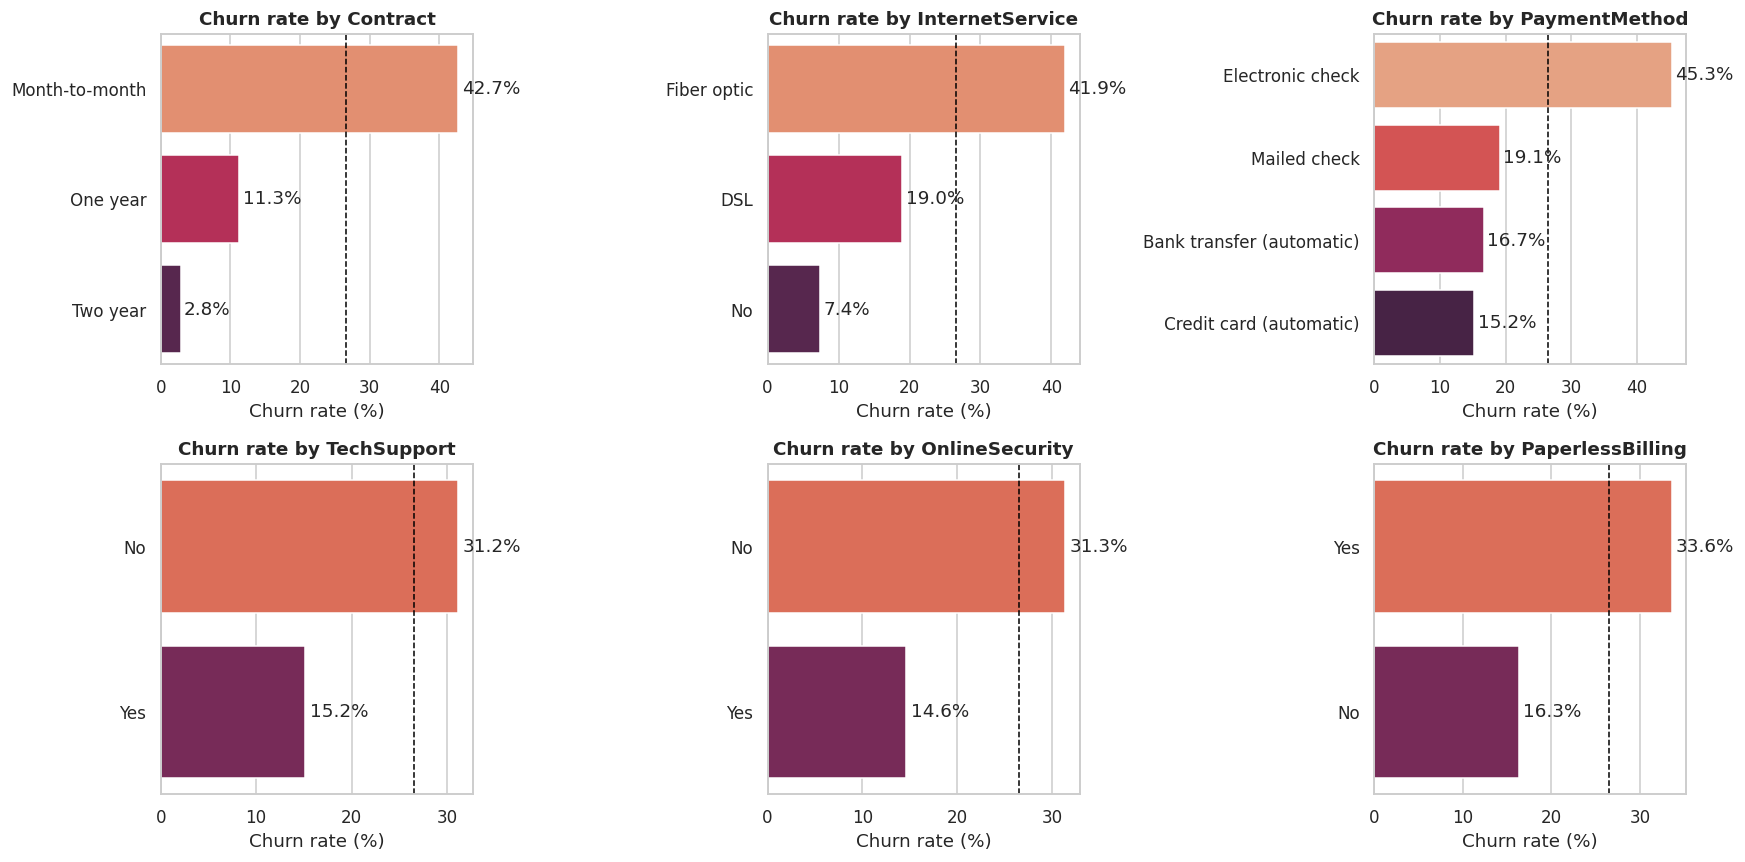

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity","PaperlessBilling"]):
    rate = df.groupby(c)["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, palette="rocket_r")
    ax.axvline(df.ChurnFlag.mean()*100, color="k", ls="--", lw=1)
    for i, v in enumerate(rate.values): ax.text(v+0.5, i, f"{v:.1f}%", va="center")
    ax.set_title(f"Churn rate by {c}"); ax.set_xlabel("Churn rate (%)"); ax.set_ylabel("")
savefig("v4_churn_rate_by_category")

**What it shows:** the percentage of customers who churn within each category (dashed line = overall 26.5%). **Why:** categorical features dominate this dataset, and rates are easier to compare than raw counts.
**Insight:** month-to-month contracts churn at about 42.7% vs about 2.8% for two-year contracts. Fiber-optic customers churn at about 41.9% vs about 19% for DSL. Electronic-check payers churn most (about 45%). Customers *without* TechSupport or OnlineSecurity churn at roughly twice the rate of those who have it (about 31% vs 15%).

### Visual 5: Correlation heatmap

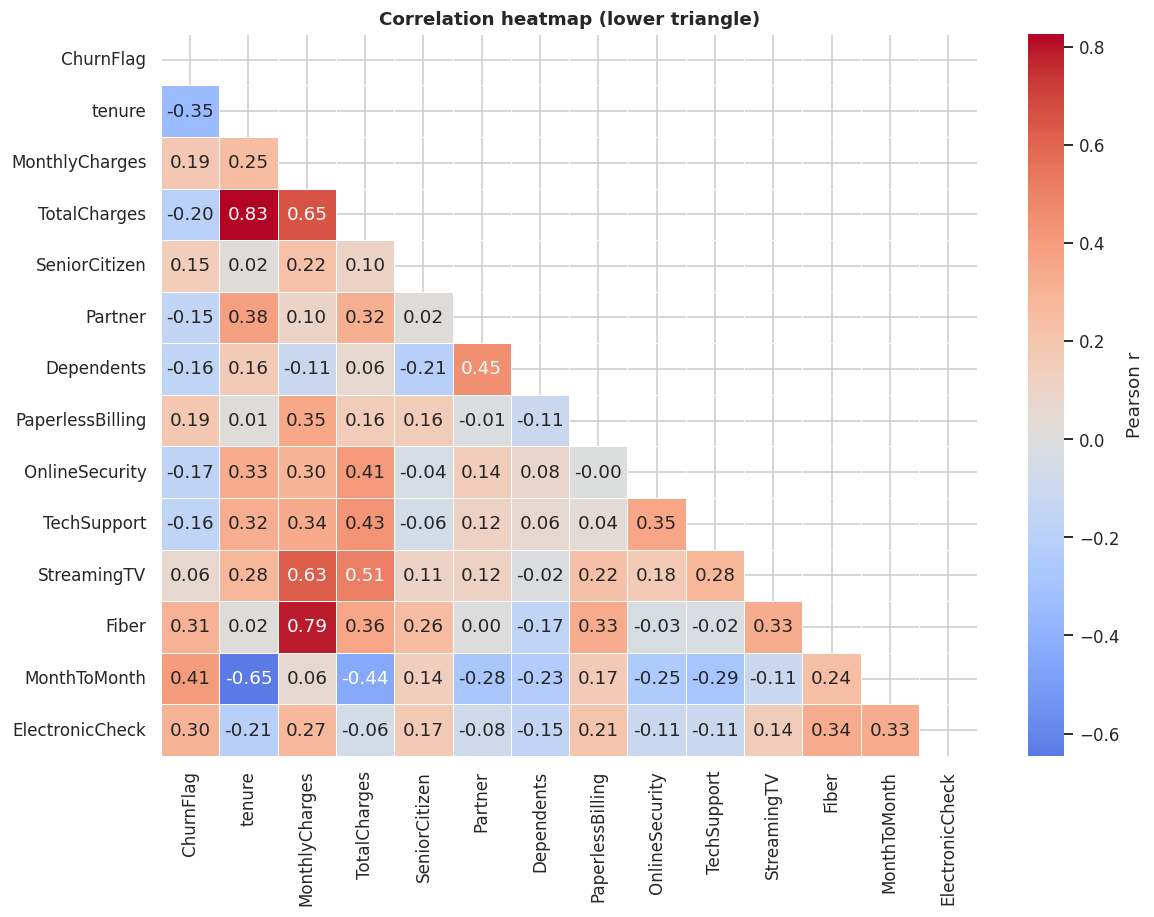

tenure             -0.352
TotalCharges       -0.198
OnlineSecurity     -0.171
TechSupport        -0.165
Dependents         -0.164
Partner            -0.150
StreamingTV         0.063
SeniorCitizen       0.151
PaperlessBilling    0.192
MonthlyCharges      0.193
ElectronicCheck     0.302
Fiber               0.308
MonthToMonth        0.405


In [15]:
# Numeric view of the data (binary Yes/No mapped to 1/0) so that all fields can be correlated
corr_df = df.copy()
for c in ["Partner","Dependents","PhoneService","PaperlessBilling","MultipleLines","OnlineSecurity","OnlineBackup",
          "DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]:
    corr_df[c] = (corr_df[c] == "Yes").astype(int)
corr_df["gender"] = (corr_df["gender"] == "Male").astype(int)
corr_df["Fiber"] = (corr_df["InternetService"] == "Fiber optic").astype(int)
corr_df["MonthToMonth"] = (corr_df["Contract"] == "Month-to-month").astype(int)
corr_df["ElectronicCheck"] = (corr_df["PaymentMethod"] == "Electronic check").astype(int)
corr_cols = ["ChurnFlag","tenure","MonthlyCharges","TotalCharges","SeniorCitizen","Partner","Dependents","PaperlessBilling",
             "OnlineSecurity","TechSupport","StreamingTV","Fiber","MonthToMonth","ElectronicCheck"]
corr = corr_df[corr_cols].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, cbar_kws={"label":"Pearson r"})
plt.title("Correlation heatmap (lower triangle)")
savefig("v5_correlation_heatmap")
print(corr["ChurnFlag"].drop("ChurnFlag").sort_values().round(3).to_string())

**What it shows:** pairwise Pearson correlation. **Why:** to find the strongest linear relationships with churn and detect multicollinearity.
**Insight:** churn correlates negatively with `tenure` (r about -0.35) and positively with `MonthToMonth` (about +0.41), `Fiber` (about +0.31) and `ElectronicCheck` (about +0.30). `TotalCharges` is highly correlated with `tenure` (about 0.83) because it is roughly tenure x monthly charge, so it is largely redundant.

### Visual 6: Scatter plot, tenure vs monthly charges

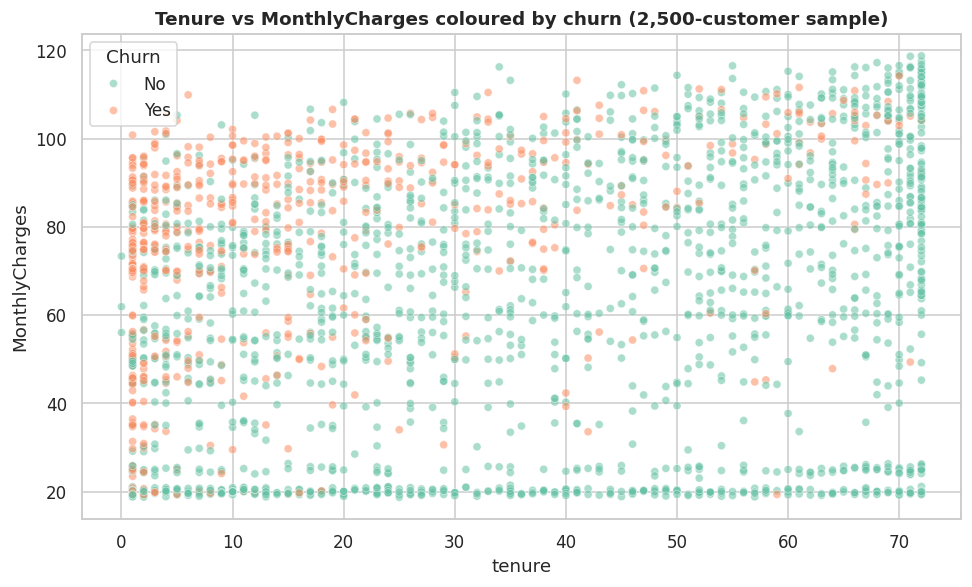

In [16]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df.sample(2500, random_state=SEED), x="tenure", y="MonthlyCharges", hue="Churn", hue_order=["No","Yes"],
                palette=["#66c2a5","#fc8d62"], alpha=.55, s=28)
plt.title("Tenure vs MonthlyCharges coloured by churn (2,500-customer sample)")
savefig("v6_scatter_tenure_monthly")

**What it shows:** every point is a customer. **Why:** to see two numeric drivers together and spot clusters.
**Insight:** churners concentrate in the **top-left** (short tenure + high charges). Customers who survive past roughly 40 months rarely churn regardless of price.

### Visual 7: Pair plot of numeric features

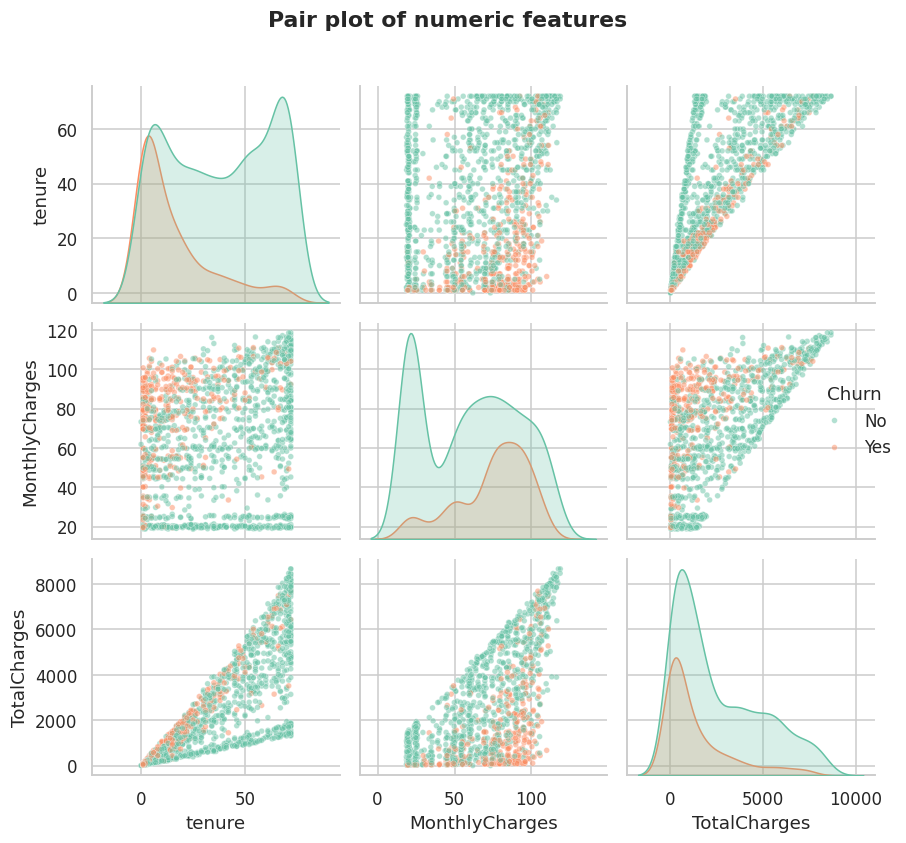

In [17]:
g = sns.pairplot(df.sample(1500, random_state=SEED), vars=numeric_cols, hue="Churn", hue_order=["No","Yes"],
                 palette=["#66c2a5","#fc8d62"], plot_kws={"alpha":.5, "s":14}, diag_kind="kde")
g.fig.suptitle("Pair plot of numeric features", y=1.02, fontweight="bold")
savefig("v7_pairplot")

**What it shows:** all pairwise scatter plots and KDEs per class. **Why:** a one-shot multivariate check for separability.
**Insight:** the churn class has a density peak at low tenure in the diagonal plot. The `tenure`-`TotalCharges` relationship is a near-fan shape, which confirms redundancy. No single numeric pair separates the classes perfectly, so a non-linear model is justified.

### Visual 8: Churn heat-map, Contract x Tenure group

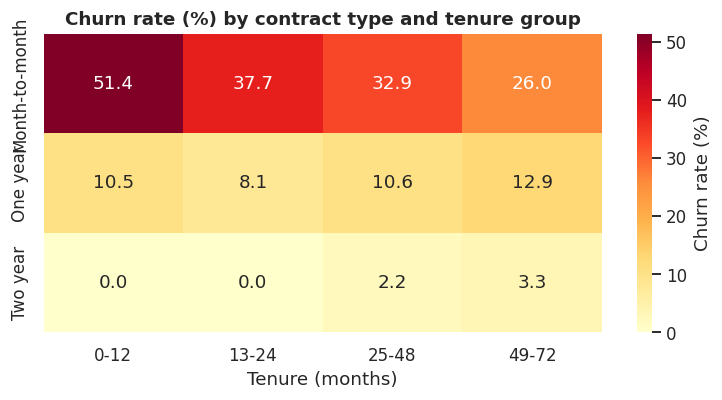

In [18]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1,12,24,48,72], labels=["0-12","13-24","25-48","49-72"])
pivot = df.pivot_table(index="Contract", columns="TenureGroup", values="ChurnFlag", aggfunc="mean").mul(100)
plt.figure(figsize=(7, 3.8))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label":"Churn rate (%)"})
plt.title("Churn rate (%) by contract type and tenure group"); plt.ylabel(""); plt.xlabel("Tenure (months)")
savefig("v8_heatmap_contract_tenure")

**What it shows:** churn rate in each contract-by-tenure cell. **Why:** a two-factor view of the two strongest drivers.
**Insight:** month-to-month customers in their first year churn at about 51%. Two-year contracts stay at or below about 3% at every tenure. The retention lever is to move new customers off month-to-month contracts.

### 4.2 Probability distributions (CO4)
We (a) fit continuous distributions to numeric fields, (b) check normality with a Q-Q plot and tests, and (c) model discrete counts with Bernoulli / Binomial distributions.

In [19]:
# ---- Continuous: fit candidate distributions to MonthlyCharges and tenure; compare with Kolmogorov-Smirnov ----
cands = {"norm": stats.norm, "lognorm": stats.lognorm, "gamma": stats.gamma, "expon": stats.expon, "weibull_min": stats.weibull_min}
res = []
for col in ["MonthlyCharges", "tenure"]:
    x = df[col][df[col] > 0].values
    for name, dist in cands.items():
        params = dist.fit(x)
        ks = stats.kstest(x, name, args=params)
        res.append([col, name, round(ks.statistic, 4), ks.pvalue])
fit_tbl = pd.DataFrame(res, columns=["feature", "distribution", "KS_stat", "p_value"])
fit_tbl.sort_values(["feature","KS_stat"])

,feature,distribution,KS_stat,p_value
2,MonthlyCharges,gamma,0.1258,1.174392e-97
0,MonthlyCharges,norm,0.1262,2.976198e-98
1,MonthlyCharges,lognorm,0.1262,2.969951e-98
4,MonthlyCharges,weibull_min,0.1299,4.246787e-104
3,MonthlyCharges,expon,0.1961,8.838582e-238
5,tenure,norm,0.1108,1.269123e-75
8,tenure,expon,0.1121,1.861152e-77
9,tenure,weibull_min,0.1569,1.151714e-151
7,tenure,gamma,0.2198,1.086671e-298
6,tenure,lognorm,0.4238,0.000000e+00


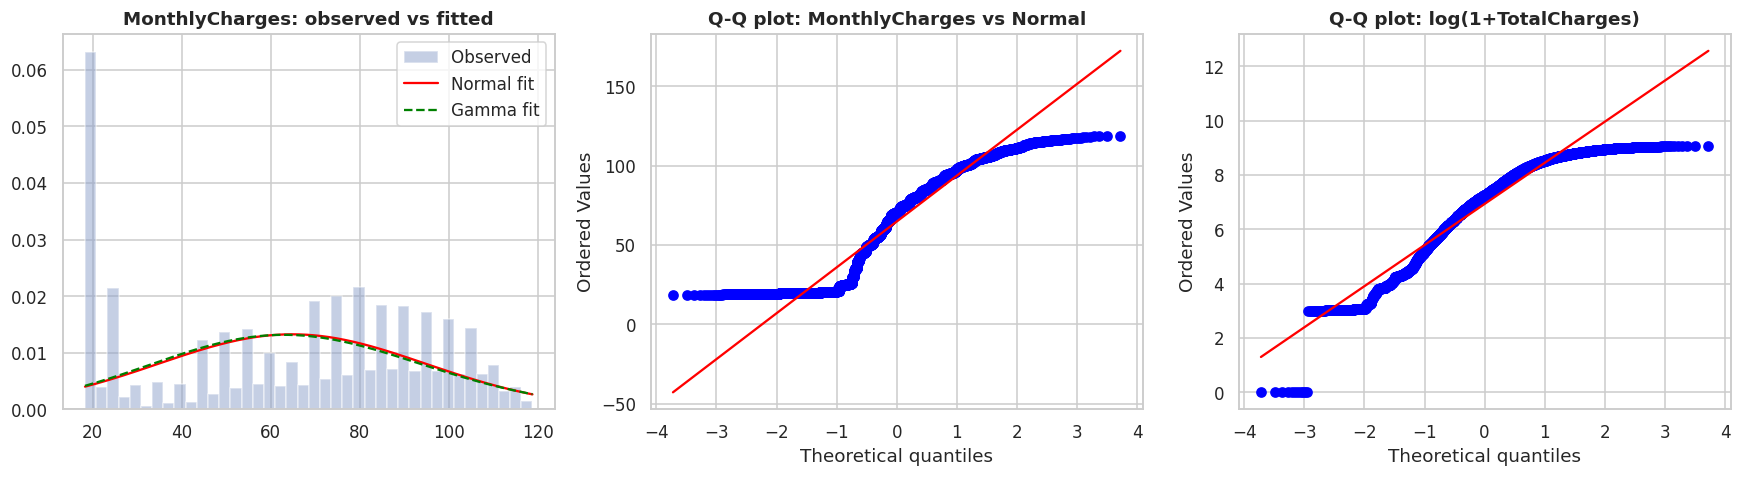

tenure          D'Agostino K2 p = 0.00e+00 -> NOT normal
MonthlyCharges  D'Agostino K2 p = 0.00e+00 -> NOT normal
TotalCharges    D'Agostino K2 p = 2.60e-176 -> NOT normal


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
# Panel A: MonthlyCharges with normal vs gamma fits
x = df["MonthlyCharges"].values; grid = np.linspace(x.min(), x.max(), 300)
axes[0].hist(x, bins=40, density=True, alpha=.5, color="#8da0cb", label="Observed")
axes[0].plot(grid, stats.norm.pdf(grid, *stats.norm.fit(x)), "r-", label="Normal fit")
axes[0].plot(grid, stats.gamma.pdf(grid, *stats.gamma.fit(x)), "g--", label="Gamma fit")
axes[0].set_title("MonthlyCharges: observed vs fitted"); axes[0].legend()
# Panel B: Q-Q plot against normal
stats.probplot(x, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot: MonthlyCharges vs Normal")
# Panel C: Q-Q plot for TotalCharges after log transform
stats.probplot(np.log1p(df["TotalCharges"]), dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot: log(1+TotalCharges)")
savefig("v9_distribution_fits_qq")

# Normality tests (D'Agostino K^2 is reliable for large n; Shapiro on a 5000-sample)
for c in numeric_cols:
    k2 = stats.normaltest(df[c]); print(f"{c:15s} D'Agostino K2 p = {k2.pvalue:.2e} -> {'NOT normal' if k2.pvalue<0.05 else 'normal'}")

**Interpretation:** none of the three numeric features is normal (p << 0.05), and `MonthlyCharges` is multimodal so no single parametric curve fits well (all KS p-values are tiny). The Q-Q plots bend away from the diagonal. `TotalCharges` is right-skewed (skew 0.96), but a log transform over-corrects it (skew becomes about -0.82), so the log is not an automatic fix. For a neural network we rely on standardization instead. For a neural network we still standardize, which is enough since the network does not assume normality.

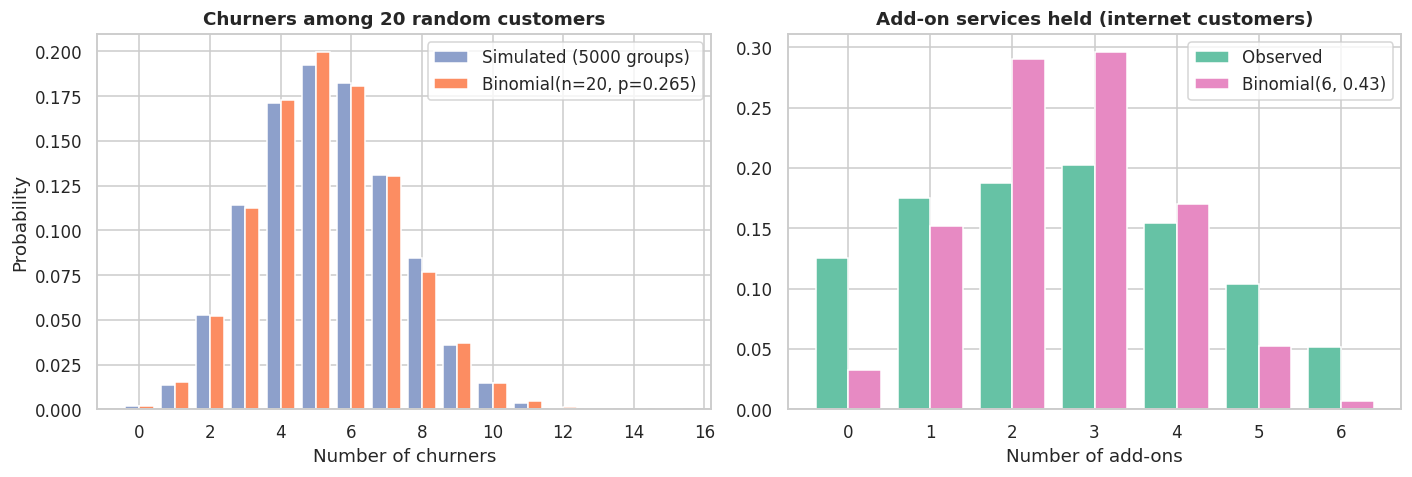

Binomial: E[churners in 20] = 5.31  SD = 1.97
P(at least 8 churners among 20) = 0.1345


In [21]:
# ---- Discrete 1: Bernoulli / Binomial model for churn ----
p = df.ChurnFlag.mean(); n = 20
k = np.arange(0, 16)
pmf = stats.binom.pmf(k, n, p)
# Empirical: draw many random groups of 20 customers and count churners in each group
rng = np.random.default_rng(SEED)
sim = np.array([df.ChurnFlag.sample(n, random_state=int(s)).sum() for s in rng.integers(0, 10**6, 5000)])
emp = np.bincount(sim, minlength=16)[:16] / len(sim)

# ---- Discrete 2: number of add-on services per customer (0..6) ----
addons = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
df["n_addons"] = (df[addons] == "Yes").sum(axis=1)
inet = df[df.InternetService != "No"]["n_addons"]       # only internet customers can buy add-ons
pb = inet.mean() / 6
obs = inet.value_counts(normalize=True).sort_index().reindex(range(7), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(k-0.2, emp, width=.4, label="Simulated (5000 groups)", color="#8da0cb")
axes[0].bar(k+0.2, pmf, width=.4, label=f"Binomial(n=20, p={p:.3f})", color="#fc8d62")
axes[0].set_title("Churners among 20 random customers"); axes[0].set_xlabel("Number of churners"); axes[0].set_ylabel("Probability"); axes[0].legend()
axes[1].bar(np.arange(7)-0.2, obs.values, width=.4, label="Observed", color="#66c2a5")
axes[1].bar(np.arange(7)+0.2, stats.binom.pmf(np.arange(7), 6, pb), width=.4, label=f"Binomial(6, {pb:.2f})", color="#e78ac3")
axes[1].set_title("Add-on services held (internet customers)"); axes[1].set_xlabel("Number of add-ons"); axes[1].legend()
savefig("v10_discrete_distributions")
print("Binomial: E[churners in 20] =", round(n*p,2), " SD =", round(np.sqrt(n*p*(1-p)),2))
print("P(at least 8 churners among 20) = %.4f" % stats.binom.sf(7, n, p))

**Interpretation:** the number of churners in a random group of 20 follows the Binomial(20, 0.265) distribution closely (expected about 5.3, SD about 1.97), so the churn process is well described as independent Bernoulli trials at the population level. The add-on count does **not** follow a binomial: the observed distribution is more spread out (12.6% of internet customers hold no add-on and 5.1% hold all six, versus about 3% and under 1% expected under a binomial). This over-dispersion means that add-on purchases are not independent: some customers buy bundles, others buy none. It is a case where a distribution assumption fails, so add-ons should be modelled jointly, which the MLP does.

### 4.3 Bivariate / multivariate hypothesis tests

In [22]:
# --- Numeric vs churn: Mann-Whitney U (non-parametric, since features are not normal) ---
rows = []
for c in numeric_cols:
    a, b = df.loc[df.ChurnFlag==0, c], df.loc[df.ChurnFlag==1, c]
    u = stats.mannwhitneyu(a, b); rbc = 1 - 2*u.statistic/(len(a)*len(b))   # rank-biserial effect size
    rows.append([c, u.pvalue, round(rbc, 3)])
print(pd.DataFrame(rows, columns=["feature","MWU_p_value","rank_biserial_effect"]).to_string(index=False))

# --- Categorical vs churn: chi-square test of independence + Cramer's V effect size ---
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
rows = []
for c in cat_cols + ["SeniorCitizen"]:
    ct = pd.crosstab(df[c], df["Churn"]); chi2, p_, dof, _ = stats.chi2_contingency(ct)
    rows.append([c, round(chi2,1), p_, round(cramers_v(ct),3)])
chi_tbl = pd.DataFrame(rows, columns=["feature","chi2","p_value","cramers_V"]).sort_values("cramers_V", ascending=False)
chi_tbl.round(4)

       feature   MWU_p_value  rank_biserial_effect
        tenure 2.419636e-208                -0.480
MonthlyCharges  3.311628e-54                 0.242
  TotalCharges  5.685034e-83                -0.301


,feature,chi2,p_value,cramers_V
12,Contract,1184.6,0.0000,0.410
5,InternetService,732.3,0.0000,0.322
14,PaymentMethod,648.1,0.0000,0.303
13,PaperlessBilling,258.3,0.0000,0.191
6,OnlineSecurity,205.6,0.0000,0.171
9,TechSupport,190.2,0.0000,0.164
2,Dependents,189.1,0.0000,0.164
1,Partner,158.7,0.0000,0.150
15,SeniorCitizen,159.4,0.0000,0.150
7,OnlineBackup,47.3,0.0000,0.082


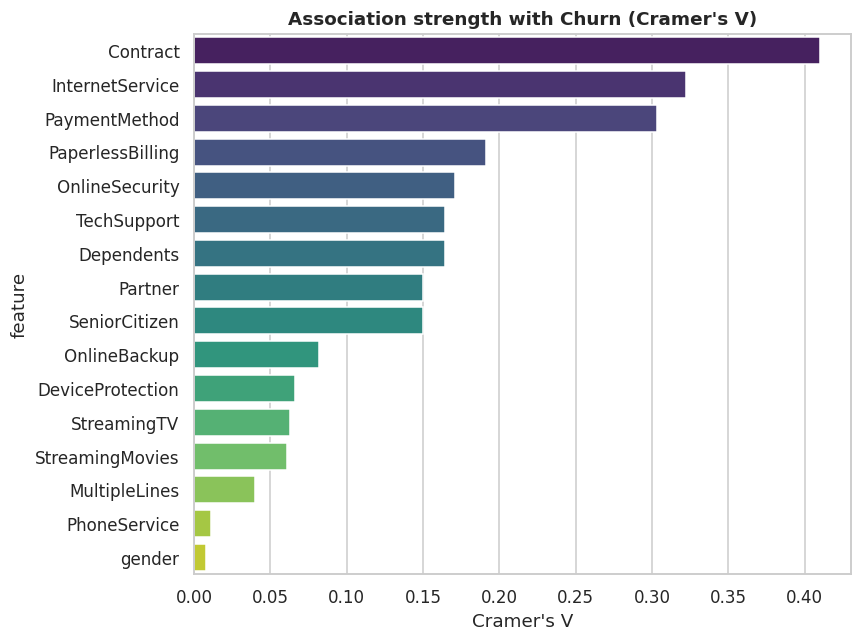

In [23]:
plt.figure(figsize=(8, 6))
sns.barplot(data=chi_tbl, x="cramers_V", y="feature", palette="viridis")
plt.title("Association strength with Churn (Cramer's V)"); plt.xlabel("Cramer's V")
savefig("v11_cramers_v")

**Interpretation:** all numeric features differ significantly between churners and non-churners, with `tenure` giving the largest effect. Among categorical features, `Contract` has the strongest association (Cramer's V = 0.41), followed by `InternetService` (0.32) and `PaymentMethod` (0.30), then `PaperlessBilling`, `OnlineSecurity` and `TechSupport` (about 0.17-0.19). `gender` and `PhoneService` are statistically unrelated to churn (p > 0.05) and are expected to contribute little to the model.

## Stage 6: REFINE: Preprocessing for modelling
Steps: encode categoricals, split into train/validation/test (stratified), then standardize using **training-set statistics only** (avoids data leakage).

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

model_df = df.drop(columns=["Churn", "TenureGroup", "n_addons"]).copy()
y = model_df.pop("ChurnFlag").values

# Binary Yes/No and gender -> 0/1 ; multi-class -> one-hot (drop_first avoids the dummy variable trap)
bin_cols = ["Partner","Dependents","PhoneService","PaperlessBilling","MultipleLines","OnlineSecurity","OnlineBackup",
            "DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
for c in bin_cols: model_df[c] = (model_df[c] == "Yes").astype(int)
model_df["gender"] = (model_df["gender"] == "Male").astype(int)
X = pd.get_dummies(model_df, columns=["InternetService","Contract","PaymentMethod"], drop_first=True).astype(float)
print("Feature matrix:", X.shape); print(list(X.columns))

# 70 / 15 / 15 stratified split
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15/0.85, stratify=y_tmp, random_state=SEED)

# Standardize numeric columns (fit on train only)
scaler = StandardScaler().fit(X_train[numeric_cols])
for part in (X_train, X_val, X_test):
    part[numeric_cols] = scaler.transform(part[numeric_cols])

print(f"Train {X_train.shape[0]} | Val {X_val.shape[0]} | Test {X_test.shape[0]}")
print("Churn rate  train/val/test:", [round(v.mean(),3) for v in (y_train, y_val, y_test)])

Feature matrix: (7043, 23)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
Train 4929 | Val 1057 | Test 1057
Churn rate  train/val/test: [np.float64(0.265), np.float64(0.266), np.float64(0.265)]


### Feature analysis (before modelling)
Mutual information captures non-linear dependence between each feature and churn.

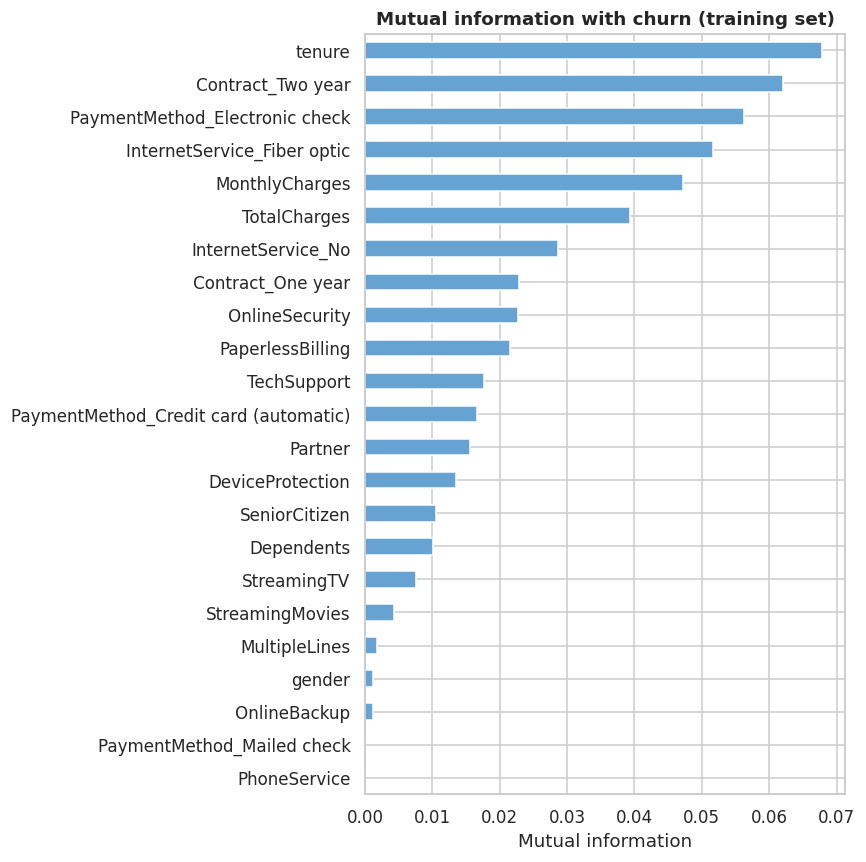

tenure                            0.0679
Contract_Two year                 0.0620
PaymentMethod_Electronic check    0.0563
InternetService_Fiber optic       0.0516
MonthlyCharges                    0.0471
TotalCharges                      0.0393
InternetService_No                0.0287
Contract_One year                 0.0229


In [25]:
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=SEED), index=X_train.columns).sort_values()
plt.figure(figsize=(8, 8)); mi.plot.barh(color="#66a3d2")
plt.title("Mutual information with churn (training set)"); plt.xlabel("Mutual information")
savefig("v12_mutual_information")
print(mi.sort_values(ascending=False).head(8).round(4).to_string())

**Insight:** `tenure`, `Contract_Two year`, `PaymentMethod_Electronic check`, `InternetService_Fiber optic` and `MonthlyCharges` carry the most information about churn, matching the earlier statistical tests. `gender` and `PhoneService` are near zero, so they could be dropped without much loss.

## Stage 7: INTERACT: Interactive exploration
A Plotly chart lets the reader hover, zoom and filter. The HTML file is saved to `figures/`.

In [26]:
import plotly.express as px
fig = px.scatter(df.sample(2000, random_state=SEED), x="tenure", y="MonthlyCharges", color="Churn", symbol="Contract",
                 hover_data=["InternetService", "PaymentMethod", "TotalCharges"],
                 color_discrete_map={"No":"#66c2a5","Yes":"#fc8d62"}, title="Interactive: tenure vs monthly charges")
fig.write_html(f"{FIG_DIR}/interactive_scatter.html")
fig.show() if False else print("Interactive chart saved to figures/interactive_scatter.html (open in a browser)")

Interactive chart saved to figures/interactive_scatter.html (open in a browser)


# Deep Learning Model: Multi-Layer Perceptron (MLP)

**Why an MLP?** The data is tabular with mixed binary/one-hot/numeric features and non-linear interactions (e.g. contract x tenure). An MLP with batch-norm and dropout is a standard deep-learning baseline for this kind of data.

**Task:** binary classification (churn = 1).

In [27]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

# Class weights compensate for the 73.5 / 26.5 imbalance
cw = {0: len(y_train) / (2*np.sum(y_train==0)), 1: len(y_train) / (2*np.sum(y_train==1))}
print("Class weights:", {k: round(v,3) for k,v in cw.items()})

def build_mlp(input_dim, units=(64, 32), dropout=0.3, lr=1e-3, l2=1e-4):
    # Fully-connected network: [Dense -> BatchNorm -> ReLU -> Dropout] x N  ->  Dense(1, sigmoid)
    inp = keras.Input(shape=(input_dim,))
    x = inp
    for u in units:
        x = layers.Dense(u, kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

build_mlp(X_train.shape[1]).summary()

I0000 00:00:1792042281.674638    6037 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792042282.955805    6037 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Class weights: {0: np.float64(0.681), 1: np.float64(1.884)}


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 23)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

## Hyperparameter tuning (basic grid search)
We tune hidden-layer sizes, dropout rate and learning rate using **validation AUC**. The test set is never touched during tuning.

In [28]:
import itertools, time
grid = {"units": [(32,), (64, 32), (128, 64, 32)], "dropout": [0.2, 0.4], "lr": [1e-3, 3e-3]}
early = lambda: keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)
results = []; t0 = time.time()
for units, dr, lr in itertools.product(grid["units"], grid["dropout"], grid["lr"]):
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(X_train.shape[1], units, dr, lr)
    h = m.fit(X_train.values, y_train, validation_data=(X_val.values, y_val), epochs=60, batch_size=128,
              class_weight=cw, callbacks=[early()], verbose=0)
    results.append({"units": str(units), "dropout": dr, "lr": lr, "best_val_auc": max(h.history["val_auc"]),
                    "epochs_run": len(h.history["loss"])})
tune = pd.DataFrame(results).sort_values("best_val_auc", ascending=False).reset_index(drop=True)
print(f"Grid search finished in {time.time()-t0:.0f}s")
tune.round(4)

Grid search finished in 88s


,units,dropout,lr,best_val_auc,epochs_run
0,"(128, 64, 32)",0.4,0.003,0.8301,16
1,"(64, 32)",0.2,0.003,0.8297,12
2,"(32,)",0.4,0.001,0.8295,37
3,"(64, 32)",0.4,0.001,0.8294,15
4,"(128, 64, 32)",0.2,0.003,0.8292,11
5,"(64, 32)",0.2,0.001,0.8292,15
6,"(32,)",0.4,0.003,0.8290,18
7,"(32,)",0.2,0.003,0.8287,19
8,"(32,)",0.2,0.001,0.8287,37
9,"(64, 32)",0.4,0.003,0.8287,15


Best configuration:
 units           (128, 64, 32)
dropout                   0.4
lr                      0.003
best_val_auc         0.830051
epochs_run                 16
Name: 0, dtype: object


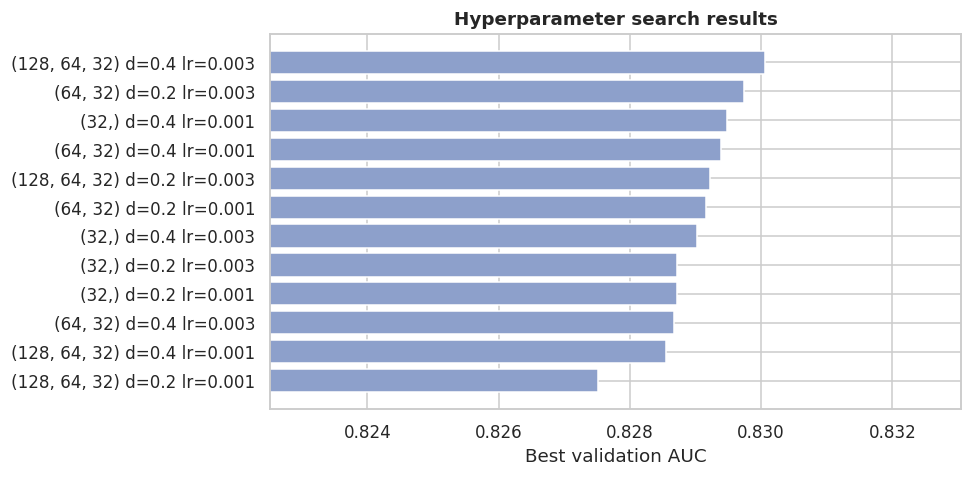

In [29]:
best = tune.iloc[0]; print("Best configuration:\n", best)
import ast
BEST_UNITS = ast.literal_eval(best["units"]); BEST_DROPOUT = float(best["dropout"]); BEST_LR = float(best["lr"])

plt.figure(figsize=(9, 4.5))
lab = tune.apply(lambda r: f"{r.units} d={r.dropout} lr={r.lr}", axis=1)
plt.barh(lab[::-1], tune["best_val_auc"][::-1], color="#8da0cb"); plt.xlim(tune.best_val_auc.min()-0.005, tune.best_val_auc.max()+0.003)
plt.xlabel("Best validation AUC"); plt.title("Hyperparameter search results")
savefig("v13_hyperparameter_search")

## Final model training

In [30]:
tf.keras.utils.set_random_seed(SEED)
model = build_mlp(X_train.shape[1], BEST_UNITS, BEST_DROPOUT, BEST_LR)
callbacks = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)]
history = model.fit(X_train.values, y_train, validation_data=(X_val.values, y_val), epochs=100, batch_size=128,
                    class_weight=cw, callbacks=callbacks, verbose=0)
print("Epochs trained:", len(history.history["loss"]))

Epochs trained: 18


# Model Evaluation and Result Visualization
### Result 1 and 2: Loss vs Epoch and Accuracy vs Epoch

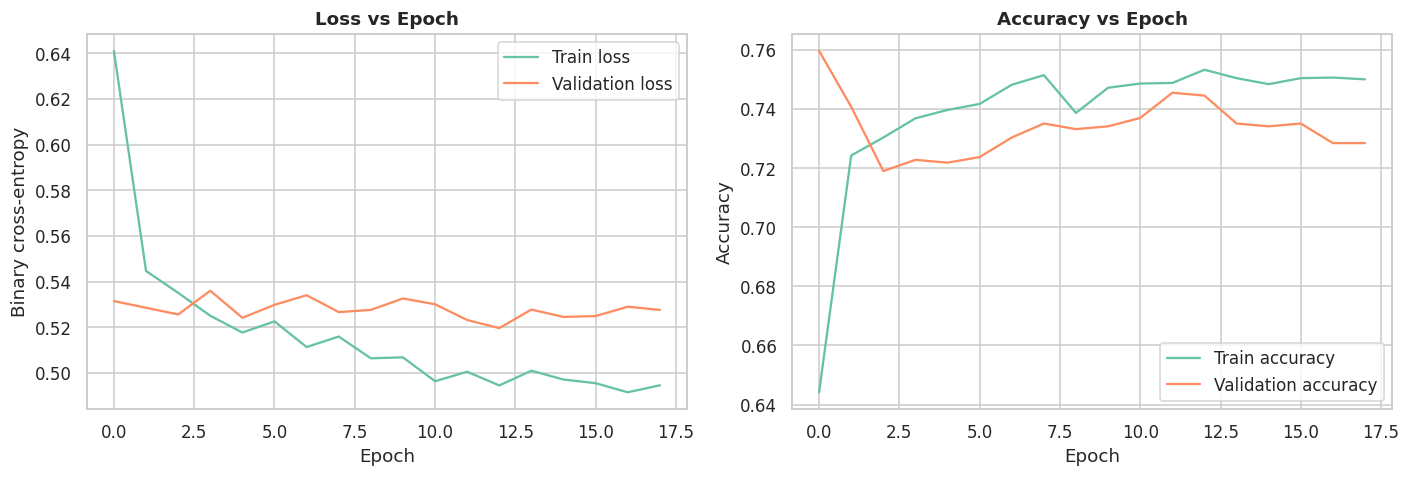

In [31]:
hist = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(hist["loss"], label="Train loss"); ax[0].plot(hist["val_loss"], label="Validation loss")
ax[0].set_title("Loss vs Epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Binary cross-entropy"); ax[0].legend()
ax[1].plot(hist["accuracy"], label="Train accuracy"); ax[1].plot(hist["val_accuracy"], label="Validation accuracy")
ax[1].set_title("Accuracy vs Epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()
savefig("r1_loss_accuracy_curves")

**Interpretation:** training loss keeps falling, while validation loss flattens at about 0.52-0.53 after the first few epochs. The widening gap shows that mild over-fitting starts early, which is why dropout, L2 regularization, learning-rate reduction and early stopping (best-AUC weights restored after 18 epochs) are used. Accuracy is measured at a 0.5 threshold on a class-weighted model, so it sits below the 73.5% majority-class figure on some epochs; this is expected, because the model deliberately trades accuracy for recall on the minority class. AUC, recall and F1 are the more informative metrics.

### Result 3: Confusion matrix, Result 4: ROC curve and AUC

Threshold chosen on validation set: 0.63


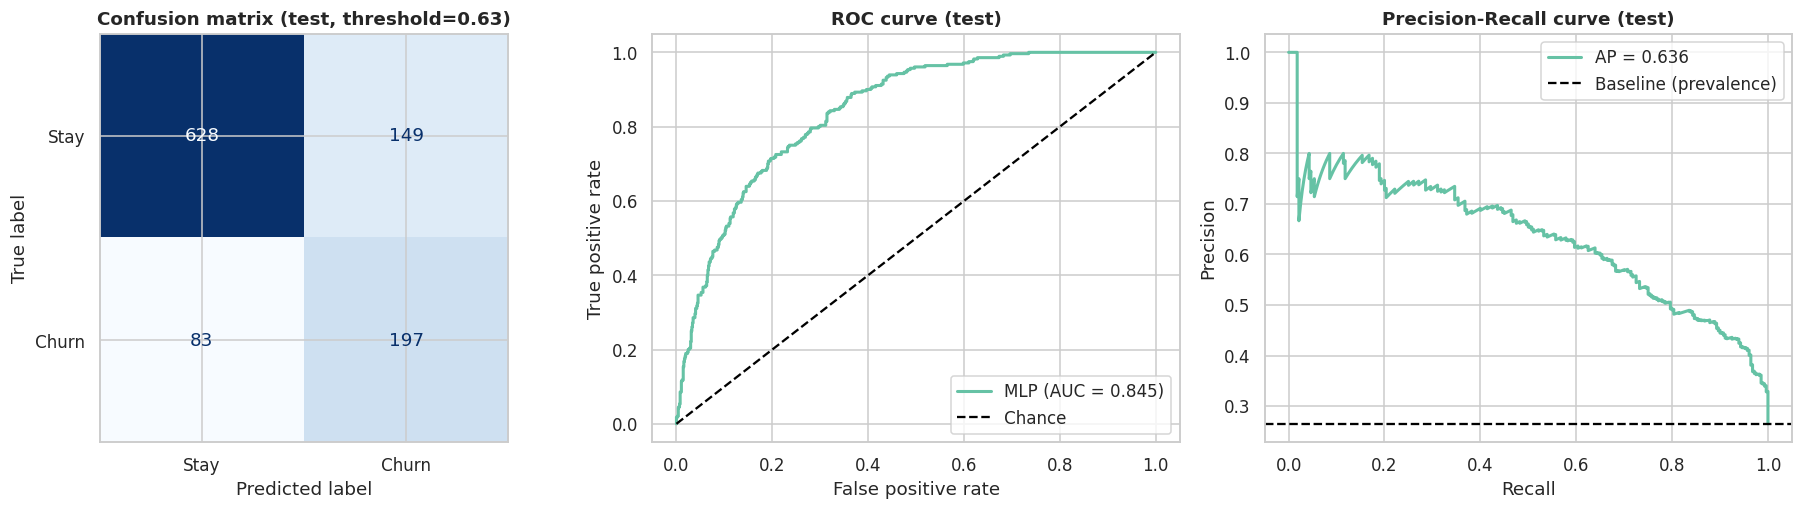

              precision    recall  f1-score   support

        Stay      0.883     0.808     0.844       777
       Churn      0.569     0.704     0.629       280

    accuracy                          0.781      1057
   macro avg      0.726     0.756     0.737      1057
weighted avg      0.800     0.781     0.787      1057



In [32]:
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score, precision_recall_curve, average_precision_score)
p_test = model.predict(X_test.values, verbose=0).ravel()
p_val  = model.predict(X_val.values, verbose=0).ravel()

# Choose the decision threshold on the VALIDATION set (maximise F1), then apply once to the test set
ths = np.linspace(0.2, 0.8, 61)
best_th = ths[np.argmax([f1_score(y_val, p_val >= t) for t in ths])]
print(f"Threshold chosen on validation set: {best_th:.2f}")
pred_test = (p_test >= best_th).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Stay","Churn"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix (test, threshold={best_th:.2f})")
fpr, tpr, _ = roc_curve(y_test, p_test); auc = roc_auc_score(y_test, p_test)
ax[1].plot(fpr, tpr, lw=2, label=f"MLP (AUC = {auc:.3f})"); ax[1].plot([0,1],[0,1],"k--", label="Chance")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC curve (test)"); ax[1].legend()
pr, rc, _ = precision_recall_curve(y_test, p_test); ap = average_precision_score(y_test, p_test)
ax[2].plot(rc, pr, lw=2, label=f"AP = {ap:.3f}"); ax[2].axhline(y_test.mean(), color="k", ls="--", label="Baseline (prevalence)")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("Precision-Recall curve (test)"); ax[2].legend()
savefig("r2_confusion_roc_pr")
print(classification_report(y_test, pred_test, target_names=["Stay","Churn"], digits=3))

**Interpretation:** the confusion matrix shows how many churners are caught (bottom-right) versus missed (bottom-left). The ROC curve sits well above the diagonal; the AUC measures the probability that a random churner gets a higher score than a random non-churner. The precision-recall curve is the more honest view for an imbalanced problem: precision is far above the 26.5% prevalence baseline across a wide range of recall.

### Result 5: Score distribution and calibration

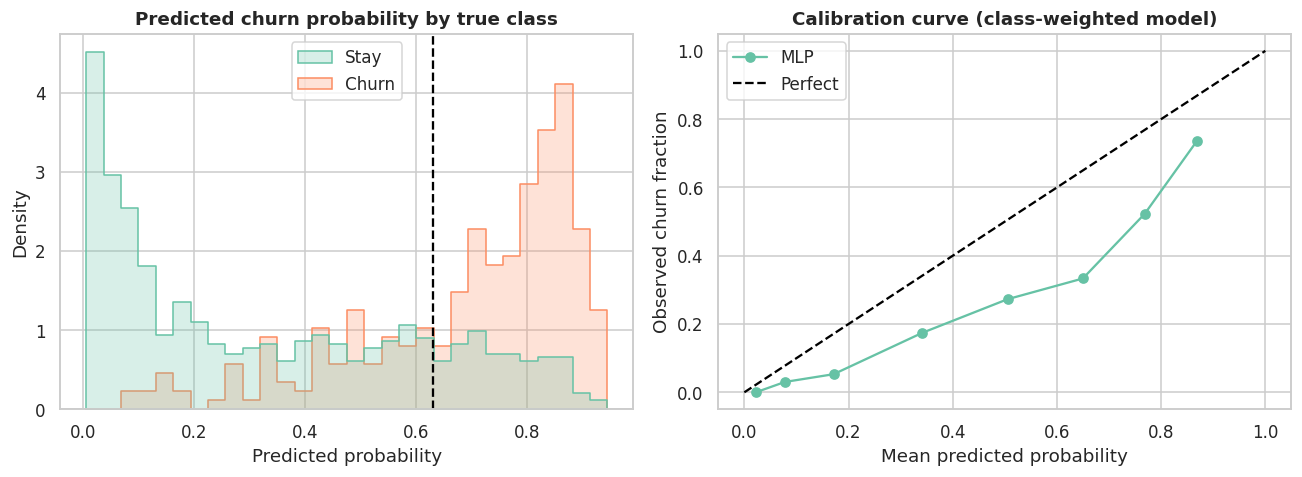

In [33]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(x=p_test, hue=np.where(y_test==1,"Churn","Stay"), bins=30, stat="density", common_norm=False, element="step", ax=ax[0], palette={"Churn":"#fc8d62","Stay":"#66c2a5"}, hue_order=["Stay","Churn"])
ax[0].axvline(best_th, color="k", ls="--"); ax[0].set_title("Predicted churn probability by true class"); ax[0].set_xlabel("Predicted probability")
fp, mp = calibration_curve(y_test, p_test, n_bins=8, strategy="quantile")
ax[1].plot(mp, fp, "o-", label="MLP"); ax[1].plot([0,1],[0,1],"k--", label="Perfect"); ax[1].set_xlabel("Mean predicted probability")
ax[1].set_ylabel("Observed churn fraction"); ax[1].set_title("Calibration curve (class-weighted model)"); ax[1].legend()
savefig("r3_score_distribution_calibration")

**Interpretation:** the two class score distributions are clearly separated but overlap in the middle (the hard-to-classify customers). Because we trained with class weights, predicted probabilities are *over-estimated* relative to true churn frequency (curve lies below the diagonal). The ranking is still good (high AUC), but if actual probabilities are needed, a calibration step (e.g. isotonic regression) should be applied.

### Benchmark against classical models

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.770,0.549,0.746,0.632,0.849
Random Forest,0.761,0.532,0.804,0.640,0.850
Gradient Boosting,0.773,0.554,0.732,0.631,0.851
MLP (ours),0.781,0.569,0.704,0.629,0.845


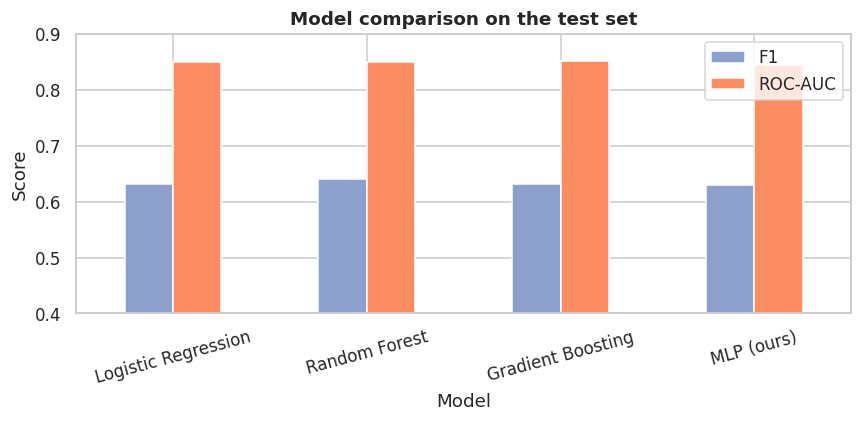

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {"Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
          "Random Forest": RandomForestClassifier(300, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1),
          "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train); pr_ = m.predict_proba(X_test)[:, 1]
    th = ths[np.argmax([f1_score(y_val, m.predict_proba(X_val)[:,1] >= t) for t in ths])]
    pd_ = (pr_ >= th).astype(int)
    rows.append([name, accuracy_score(y_test,pd_), precision_score(y_test,pd_), recall_score(y_test,pd_), f1_score(y_test,pd_), roc_auc_score(y_test,pr_)])
rows.append(["MLP (ours)", accuracy_score(y_test,pred_test), precision_score(y_test,pred_test), recall_score(y_test,pred_test), f1_score(y_test,pred_test), auc])
bench = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1","ROC-AUC"]).set_index("Model").round(3)
display(bench)
bench[["F1","ROC-AUC"]].plot.bar(figsize=(8,4), rot=15, color=["#8da0cb","#fc8d62"]); plt.ylim(0.4, 0.9)
plt.title("Model comparison on the test set"); plt.ylabel("Score")
savefig("r4_model_comparison")

**Interpretation:** the MLP (AUC 0.845) lands within about 0.005 AUC of logistic regression (0.849), random forest (0.850) and gradient boosting (0.851); the MLP is marginally lower on AUC and highest on accuracy and precision. This is typical for small tabular datasets (about 5k training rows) and suggests the signal is largely additive rather than strongly non-linear. The deep model therefore adds no measurable gain over simple baselines here, which is itself a useful finding.

### Feature importance (permutation importance on the MLP)

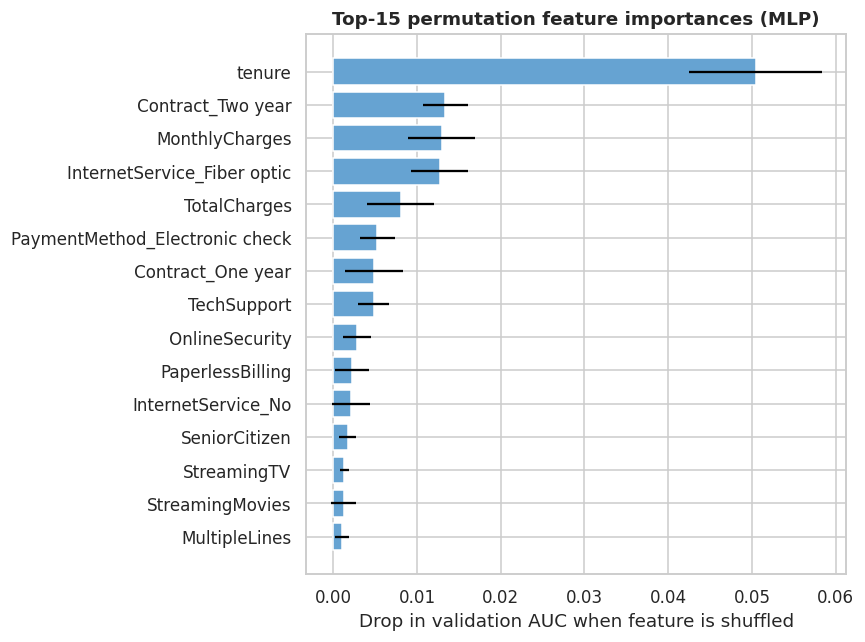

                                  mean     std
tenure                          0.0504  0.0079
Contract_Two year               0.0134  0.0027
MonthlyCharges                  0.0129  0.0040
InternetService_Fiber optic     0.0127  0.0034
TotalCharges                    0.0080  0.0040
PaymentMethod_Electronic check  0.0053  0.0021
Contract_One year               0.0048  0.0035
TechSupport                     0.0048  0.0019


In [35]:
# Permutation importance: shuffle one feature at a time on the validation set and measure the AUC drop
rng = np.random.default_rng(SEED); base = roc_auc_score(y_val, p_val); imp = {}
for col in X_val.columns:
    drops = []
    for _ in range(10):
        Xp = X_val.copy(); Xp[col] = rng.permutation(Xp[col].values)
        drops.append(base - roc_auc_score(y_val, model.predict(Xp.values, verbose=0).ravel()))
    imp[col] = (np.mean(drops), np.std(drops))
imp = pd.DataFrame(imp, index=["mean","std"]).T.sort_values("mean")
top = imp.tail(15)
plt.figure(figsize=(8, 6)); plt.barh(top.index, top["mean"], xerr=top["std"], color="#66a3d2")
plt.xlabel("Drop in validation AUC when feature is shuffled"); plt.title("Top-15 permutation feature importances (MLP)")
savefig("r5_permutation_importance")
print(imp.sort_values("mean", ascending=False).head(8).round(4).to_string())

**Interpretation:** the importance ranking confirms the EDA: `tenure`, contract type, monthly/total charges and internet service type matter most; demographics such as `gender` have near-zero importance. This agreement between statistical tests (Cramer's V), mutual information and model-based importance gives us confidence that the findings are robust.

# Conclusion and Future Scope
**What we learned:** churn (26.5%) is driven by *contract flexibility, short tenure, high monthly price, fiber service without support add-ons, and electronic-check payment*. Demographics (gender) are irrelevant.

**Model performance:** see the metrics table above (test set). On the held-out test set the MLP reaches ROC-AUC 0.845, accuracy 0.781, precision 0.569, recall 0.704 and F1 0.629 (threshold 0.63 chosen on the validation set). Classical baselines score slightly higher AUC (0.849-0.851), so the deep model is competitive but not superior.

**Challenges:** class imbalance, a hidden missing-value pattern (blank `TotalCharges` for new customers), strongly correlated features (`tenure` and `TotalCharges`), non-normal distributions, and a modest dataset size for deep learning.

**Future work:** (1) use time-series usage data and an LSTM, (2) SMOTE or focal loss for imbalance, (3) SHAP explanations, (4) cost-sensitive thresholds using customer lifetime value, (5) probability calibration, (6) cross-validation and larger datasets, (7) deploy as an API with a retention-offer recommender.